In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, accuracy_score, classification_report,
                             roc_auc_score, average_precision_score, balanced_accuracy_score,
                             recall_score, precision_score)

# Load the master dataset
df = pd.read_csv("master_dataset.csv")

# 1. Re-engineer the missing title features for the ML model
df['title_char_len'] = df['title'].astype(str).apply(len)
df['title_word_count'] = df['title'].astype(str).apply(lambda x: len(x.split()))
df['has_question_hook'] = df['title'].astype(str).apply(lambda x: 1 if '?' in x else 0)
df['has_exclamation_hook'] = df['title'].astype(str).apply(lambda x: 1 if '!' in x else 0)

# 2. Ensure target variable exists
threshold = df['engagement_rate'].quantile(0.80)
df['is_viral'] = (df['engagement_rate'] >= threshold).astype(int)

# 3. Select only independent features (Drop all direct engagement stats to prevent data leakage)
# NOTE: likes, comments, views, days_trending and views_gained are all left out on purpose.
features_to_keep = [
    'category_id', 'title_char_len', 'title_word_count',
    'has_question_hook', 'has_exclamation_hook',
    'relatability_ratio', 'hype_velocity_per_day'
]

# Create X and y
x = df[features_to_keep].copy()

# Convert categorical YouTube Category IDs into dummy variables (One-Hot Encoding)
x = pd.get_dummies(x, columns=['category_id'], drop_first=True)

y = df['is_viral']

print(f"X shape: {x.shape} | y shape: {y.shape}")
print(f"Viral share: {y.mean():.1%}")

X shape: (2143, 21) | y shape: (2143,)
Viral share: 20.0%


In [2]:
# 80/20 split -> 80% data for training and 20% for testing
# stratify=y ensures the 80/20 ratio of viral/non-viral is maintained in both sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

# The number every model has to beat: always predicting "not viral"
baseline_acc = 1 - y_test.mean()
print(f"Baseline accuracy (always predict 'not viral'): {baseline_acc:.4f}")

Training data shape: (1714, 21)
Testing data shape: (429, 21)
Baseline accuracy (always predict 'not viral'): 0.7995


In [3]:

# class_weight='balanced' makes the tree care about the rare viral class,
# otherwise almost every leaf just says "not viral"
dt_model = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=42)
dt_model.fit(x_train, y_train)

# Model Evaluation
dt_pred = dt_model.predict(x_test)
dt_prob = dt_model.predict_proba(x_test)[:, 1]

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_pred))
print("Decision Tree AUC:", roc_auc_score(y_test, dt_prob))
print("Decision Tree Viral Recall:", recall_score(y_test, dt_pred))

# Print the actual rules the tree learned
print("\nTree Rules:")
print(export_text(dt_model, feature_names=list(x.columns), max_depth=3))

Decision Tree Accuracy: 0.6386946386946387
Decision Tree AUC: 0.6856227540850227
Decision Tree Viral Recall: 0.6744186046511628

Tree Rules:
|--- relatability_ratio <= 0.34
|   |--- category_id_23 <= 0.50
|   |   |--- category_id_10 <= 0.50
|   |   |   |--- class: 0
|   |   |--- category_id_10 >  0.50
|   |   |   |--- class: 1
|   |--- category_id_23 >  0.50
|   |   |--- title_char_len <= 61.50
|   |   |   |--- class: 1
|   |   |--- title_char_len >  61.50
|   |   |   |--- class: 0
|--- relatability_ratio >  0.34
|   |--- relatability_ratio <= 0.43
|   |   |--- title_word_count <= 8.50
|   |   |   |--- class: 1
|   |   |--- title_word_count >  8.50
|   |   |   |--- class: 0
|   |--- relatability_ratio >  0.43
|   |   |--- category_id_24 <= 0.50
|   |   |   |--- class: 1
|   |   |--- category_id_24 >  0.50
|   |   |   |--- class: 0



In [4]:
# Model A: plain Random Forest (optimises overall accuracy)
rf_plain = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)
rf_plain.fit(x_train, y_train)

# Model B: balanced Random Forest (built to actually FIND viral videos)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced_subsample',
                            random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

def evaluate(name, model):
    pred = model.predict(x_test)
    prob = model.predict_proba(x_test)[:, 1]
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'AUC': roc_auc_score(y_test, prob),
        'PR-AUC': average_precision_score(y_test, prob),
        'Viral Precision': precision_score(y_test, pred, zero_division=0),
        'Viral Recall': recall_score(y_test, pred),
        'Balanced Acc': balanced_accuracy_score(y_test, pred),
    }

results = pd.DataFrame([
    {'Model': "Baseline (always 'not viral')", 'Accuracy': baseline_acc, 'AUC': 0.5, 'PR-AUC': y_test.mean(),
     'Viral Precision': 0.0, 'Viral Recall': 0.0, 'Balanced Acc': 0.5},
    evaluate("Decision Tree (balanced)", dt_model),
    evaluate("Random Forest A (plain)", rf_plain),
    evaluate("Random Forest B (balanced)", rf),
]).set_index('Model').round(3)
display(results)

rf_pred = rf.predict(x_test)
rf_prob = rf.predict_proba(x_test)[:, 1]
print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print("Random Forest AUC:", roc_auc_score(y_test, rf_prob))
print("\nClassification Report:\n", classification_report(y_test, rf_pred))

# Course rubric check (minimum accuracy 51%)
print("Rubric check (accuracy > 51%):", "PASS" if accuracy_score(y_test, rf_pred) > 0.51 else "FAIL")

,Accuracy,AUC,PR-AUC,Viral Precision,Viral Recall,Balanced Acc
Model,,,,,,
Baseline (always 'not viral'),0.800,0.500,0.200,0.000,0.000,0.500
Decision Tree (balanced),0.639,0.686,0.291,0.314,0.674,0.652
Random Forest A (plain),0.793,0.748,0.366,0.421,0.093,0.530
Random Forest B (balanced),0.704,0.751,0.365,0.348,0.547,0.645


Random Forest Accuracy: 0.703962703962704
Random Forest AUC: 0.7510000678012068

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.74      0.80       343
           1       0.35      0.55      0.43        86

    accuracy                           0.70       429
   macro avg       0.61      0.64      0.61       429
weighted avg       0.76      0.70      0.73       429

Rubric check (accuracy > 51%): PASS


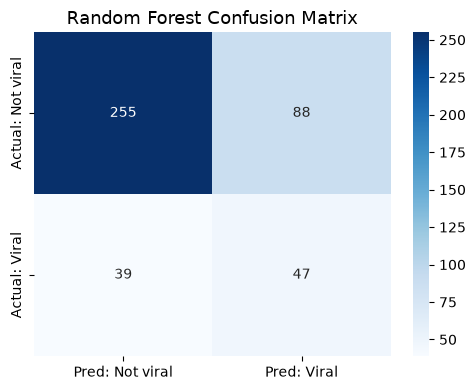

In [5]:
# Where does the model get it right and wrong?
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred: Not viral', 'Pred: Viral'],
            yticklabels=['Actual: Not viral', 'Actual: Viral'])
plt.title("Random Forest Confusion Matrix", fontsize=13)
plt.tight_layout()
plt.show()

In [6]:
# One train/test split can be lucky or unlucky -> check the AUC on 5 different splits
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def cv_auc(cols):
    model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight='balanced_subsample',
                                   random_state=42, n_jobs=-1)
    scores = cross_val_score(model, x[cols], y, cv=cv, scoring='roc_auc')
    return scores.mean(), scores.std()

all_cols = list(x.columns)
no_relat = [c for c in all_cols if c != 'relatability_ratio']
no_hype = [c for c in all_cols if c != 'hype_velocity_per_day']
creator_only = [c for c in all_cols if c not in ('relatability_ratio', 'hype_velocity_per_day')]

ablation = []
for name, cols in [("All features", all_cols),
                   ("Without relatability_ratio", no_relat),
                   ("Without hype_velocity_per_day", no_hype),
                   ("Title + category only (what a creator controls)", creator_only)]:
    m, s = cv_auc(cols)
    ablation.append({'Feature set': name, 'CV AUC (mean)': round(m, 3), 'CV AUC (std)': round(s, 3)})

ablation = pd.DataFrame(ablation).set_index('Feature set')
display(ablation)

,CV AUC (mean),CV AUC (std)
Feature set,,
All features,0.760,0.019
Without relatability_ratio,0.718,0.011
Without hype_velocity_per_day,0.756,0.019
Title + category only (what a creator controls),0.716,0.015


Top Drivers of Virality:


,feature,importance,perm_importance
4,relatability_ratio,0.370312,0.104573
0,category (all),0.224176,0.023559
5,title_char_len,0.150088,0.012925
3,hype_velocity_per_day,0.135687,0.011452
6,title_word_count,0.092145,0.010375
1,has_exclamation_hook,0.021813,0.002137
2,has_question_hook,0.005778,-0.000381


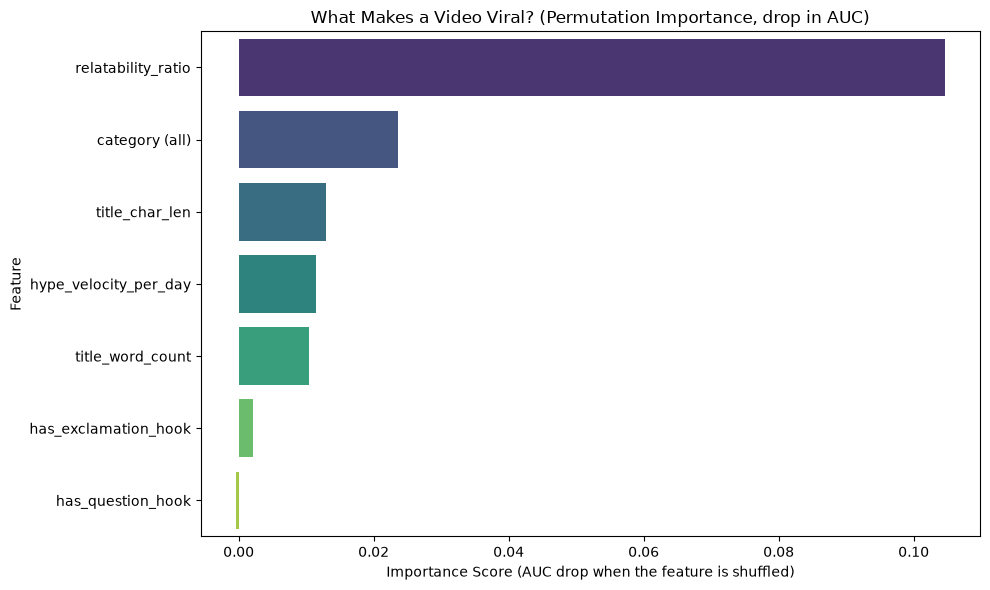

In [7]:

perm = permutation_importance(rf, x_test, y_test, scoring='roc_auc', n_repeats=20,
                              random_state=42, n_jobs=-1)

feature_importances = pd.DataFrame({
    "feature": x.columns,
    "importance": rf.feature_importances_,
    "perm_importance": perm.importances_mean
})

# Category dummies are one variable split into many columns -> add them back into one "category" score
feature_importances['feature'] = feature_importances['feature'].where(
    ~feature_importances['feature'].str.startswith('category_id_'), 'category (all)')
feature_importances = (feature_importances.groupby('feature', as_index=False).sum()
                       .sort_values('perm_importance', ascending=False))

print("Top Drivers of Virality:")
display(feature_importances.head(10))

# Visualize the top features
plt.figure(figsize=(10, 6))
sns.barplot(x='perm_importance', y='feature', hue='feature', legend=False,
            data=feature_importances.head(10), palette='viridis')
plt.title("What Makes a Video Viral? (Permutation Importance, drop in AUC)")
plt.xlabel("Importance Score (AUC drop when the feature is shuffled)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Strategy Report: What Is Linked to Engagement on Trending YouTube Videos?

The cell below fills in the final numbers automatically from the models above, so the report always matches the results. Copy its output into the final report.

In [8]:
#Took help of Gemini to help structure result for a report
auc_full = ablation.loc['All features', 'CV AUC (mean)']
auc_creator = ablation.loc['Title + category only (what a creator controls)', 'CV AUC (mean)']
rf_acc = accuracy_score(y_test, rf_pred)
rf_rec = recall_score(y_test, rf_pred)
rf_prec = precision_score(y_test, rf_pred, zero_division=0)
top3 = feature_importances['feature'].head(3).tolist()
title_corr = df[['title_char_len', 'engagement_rate']].corr(method='spearman').iloc[0, 1]
if abs(title_corr) < 0.05:
    title_dir = "title length showed no clear relationship with engagement"
    title_action = "Title length is something a creator controls, but this data gives no clear advice on it."
else:
    title_dir = "shorter titles tend to get higher engagement" if title_corr < 0 else "longer titles tend to get higher engagement"
    title_action = "Title length is something a creator controls, so this is the most actionable finding."

auc_test = roc_auc_score(y_test, rf_prob)
if auc_test < 0.60:
    signal = "That is a weak signal - the model is only a little better than guessing."
elif auc_test < 0.70:
    signal = "That is a modest signal - virality is only partly predictable."
else:
    signal = "That is a moderate signal - virality is partly predictable, but it is not a formula."

report = f"""
STRATEGY REPORT - WHAT IS LINKED TO ENGAGEMENT ON TRENDING YOUTUBE VIDEOS

Setup: {len(df):,} trending US videos. A video counts as "viral" if it is in the top 20% by engagement rate
((likes + comments) / views). I trained a Decision Tree and a Random Forest on comment sentiment, day-one
hype, title features and category.

How well did it work? The final Random Forest reached {rf_acc:.1%} accuracy (rubric minimum: 51%) and an AUC of
{auc_test:.2f}. Because only 20% of videos are viral, always guessing "not viral" already scores
{baseline_acc:.1%}, so AUC and recall are the fairer measures: the model finds {rf_rec:.0%} of viral videos, and
{rf_prec:.0%} of the videos it flags as viral really are. Across 5 different splits the AUC was {auc_full:.2f}.
{signal}

What mattered most (permutation importance): {top3[0]}, then {top3[1]}, then {top3[2]}.

Title: {title_dir} (Spearman correlation {title_corr:+.2f}). {title_action}
Exclamation marks and question marks added little.

What a creator can control: using only title and category, the AUC was {auc_creator:.2f}, compared with {auc_full:.2f}
using all features. Comment sentiment and day-one views are only known after a video is already live, so they help
describe and predict engagement but cannot be set in advance.

Limits: only trending videos are included, so results may not hold for all of YouTube. Comment sentiment and engagement
come from the same audience, so their link is an association, not proof that creators can cause engagement by shaping comments.
Feature importance shows what the model used, not what causes engagement.
"""
print(report)


STRATEGY REPORT - WHAT IS LINKED TO ENGAGEMENT ON TRENDING YOUTUBE VIDEOS

Setup: 2,143 trending US videos. A video counts as "viral" if it is in the top 20% by engagement rate
((likes + comments) / views). I trained a Decision Tree and a Random Forest on comment sentiment, day-one
hype, title features and category.

How well did it work? The final Random Forest reached 70.4% accuracy (rubric minimum: 51%) and an AUC of
0.75. Because only 20% of videos are viral, always guessing "not viral" already scores
80.0%, so AUC and recall are the fairer measures: the model finds 55% of viral videos, and
35% of the videos it flags as viral really are. Across 5 different splits the AUC was 0.76.
That is a moderate signal - virality is partly predictable, but it is not a formula.

What mattered most (permutation importance): relatability_ratio, then category (all), then title_char_len.

Title: shorter titles tend to get higher engagement (Spearman correlation -0.23). Title length is something a c